# Robustness of metric and non-metric MDS

In [1]:
import numpy as np
import pylab as plt

from sklearn.manifold import MDS
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier
from scipy.spatial.distance import pdist

plt.style.use('mpl_style.txt')

In [68]:
%%time

n = 99
dims = np.geomspace(1, 1_000_000, 30, dtype=int)
n_reps = 20

knns = np.zeros((2, len(dims), n_reps))

# Pairwise distances are equal to 10
Xclean = np.zeros((n, 2))
Xclean[: n // 3] = [0, 0]
Xclean[n // 3 : 2 * n // 3] = [10, 0]
Xclean[2 * n // 3 :] = [5, 10 * np.sqrt(3) / 2]

y = np.zeros(n)
y[n // 3 : 2 * n // 3] = 1
y[2 * n // 3 :] = 2

for rep in range(n_reps):
    X = np.concatenate(
        (Xclean, np.random.default_rng(seed=rep).normal(size=(Xclean.shape[0], np.max(dims)))),
        axis=1
    )

    mmds = MDS(normalized_stress=True, n_init=1, init="random", random_state=rep)
    nmds = MDS(normalized_stress=True, n_init=1, init="random", metric_mds=False, random_state=rep)

    for i, dim in enumerate(dims):
        print(".", end="", flush=True)
    
        Zmmds = mmds.fit_transform(X[:, : 2 + dim])
        Znmds = nmds.fit_transform(X[:, : 2 + dim])

        for j, Z in enumerate([Zmmds, Znmds]):
            acc = KNeighborsClassifier(n_neighbors=10).fit(Z, y).score(None, y)
            knns[j, i, rep] = acc
    print("")

knns = np.mean(knns, axis=2)

..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
..............................
CPU times: user 22min 51s, sys: 3.73 s, total: 22min 55s
Wall time: 8min 30s


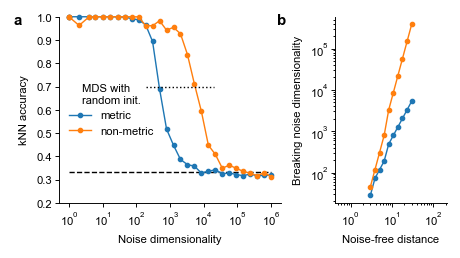

In [77]:
fig = plt.figure(figsize=(3.25, 1.8))

plt.subplot(1, 3, (1, 2))
plt.plot([dims[0], dims[-1]], [1/3, 1/3], 'k--')
plt.plot(dims, knns[0], '.-', label="metric", clip_on=False)
plt.plot(dims, knns[1], '.-', label="non-metric", clip_on=False)
plt.legend(title="MDS with\nrandom init.", loc="center left")
plt.ylim([.2, 1])
plt.xscale("log")
plt.xlabel("Noise dimensionality")
plt.ylabel("kNN accuracy")
plt.xticks([1, 10, 100, 1000, 10000, 100000, 1000000])
plt.plot([2 * 10**2, 2 * 10**4], [.7, .7], 'k:')

# Values taken from the simulation in the next cell below
clean_dists = np.geomspace(3, 30, 10)
breaking_dims = np.array(
    [[    28,     72,    117,    188,    489,    788,   1268,   2043,
          3290,   5298],
       [    45,    117,    303,    788,   3290,   8531,  22122,  57361,
        148735, 385662]]
)

plt.subplot(1, 3, 3)
plt.plot(clean_dists, breaking_dims[0], '.-', label="metric MDS")
plt.plot(clean_dists, breaking_dims[1], '.-', label="non-metric MDS")
plt.xlabel("Noise-free distance")
plt.ylabel("Breaking noise dimensionality")
plt.yscale("log")
plt.xscale("log")
plt.gca().set_aspect("equal", adjustable="datalim")

fig.text(.00, .93, "a", fontweight="bold", fontsize=8)
fig.text(.60, .93, "b", fontweight="bold", fontsize=8)

plt.savefig("figures/robustness.png", dpi=300)
plt.savefig("figures/robustness.pdf")

In [65]:
%%time

clean_dists = np.geomspace(3, 30, 10)

n = 99
dims = np.geomspace(1, 1_000_000, 30, dtype=int)
n_reps = 20

breaking_threshold = .7
breaking_dims = np.zeros((2, len(clean_dists)), dtype=int)

for clean_dist_num, clean_dist in enumerate(clean_dists):
    print(f"{clean_dist:.1f}")

    knns = np.zeros((2, len(dims), n_reps))

    Xclean = np.zeros((n, 2))
    Xclean[: n // 3] = [0, 0]
    Xclean[n // 3 : 2 * n // 3] = [clean_dist, 0]
    Xclean[2 * n // 3 :] = [clean_dist / 2, clean_dist * np.sqrt(3) / 2]

    y = np.zeros(n)
    y[n // 3 : 2 * n // 3] = 1
    y[2 * n // 3 :] = 2

    for rep in range(n_reps):
        print(".", end="", flush=True)
        
        X = np.concatenate(
            (Xclean, np.random.default_rng(seed=rep).normal(size=(Xclean.shape[0], np.max(dims)))),
            axis=1
        )
    
        mmds = MDS(normalized_stress=True, n_init=1, init="random", random_state=rep)
        nmds = MDS(normalized_stress=True, n_init=1, init="random", metric_mds=False, random_state=rep)
    
        for i, dim in enumerate(dims):
            Zmmds = mmds.fit_transform(X[:, : 2 + dim])
            Znmds = nmds.fit_transform(X[:, : 2 + dim])
    
            for j, Z in enumerate([Zmmds, Znmds]):
                acc = KNeighborsClassifier(n_neighbors=10).fit(Z, y).score(None, y)
                knns[j, i, rep] = acc
    print("")
    
    knns = np.mean(knns, axis=2)

    for i in range(2):
        breaking_dims[i, clean_dist_num] = dims[np.where(knns[i] < breaking_threshold)[0][0]]

breaking_dims

3.0
....................
3.9
....................
5.0
....................
6.5
....................
8.3
....................
10.8
....................
13.9
....................
18.0
....................
23.2
....................
30.0
....................
CPU times: user 3h 33min 46s, sys: 29.5 s, total: 3h 34min 15s
Wall time: 1h 18min 4s


array([[    28,     72,    117,    188,    489,    788,   1268,   2043,
          3290,   5298],
       [    45,    117,    303,    788,   3290,   8531,  22122,  57361,
        148735, 385662]])

In [76]:
from scipy.stats import linregress

slope_mmds, _, _, _, _ = linregress(np.log(clean_dists), np.log(breaking_dims[0]))
print(f"Slope mMDS: {slope_mmds:.1f}")

slope_nmds, _, _, _, _ = linregress(np.log(clean_dists), np.log(breaking_dims[1]))
print(f"Slope nMDS: {slope_nmds:.1f}")

Slope mMDS: 2.2
Slope nMDS: 4.0


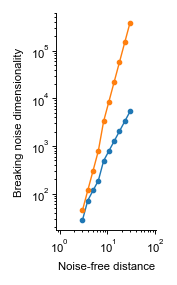

In [67]:
plt.figure(figsize=(1.2, 2))

plt.plot(clean_dists, breaking_dims[0], '.-', label="metric MDS")
plt.plot(clean_dists, breaking_dims[1], '.-', label="non-metric MDS")
plt.xlabel("Noise-free distance")
plt.ylabel("Breaking noise dimensionality")
plt.yscale("log")
plt.xscale("log")
plt.gca().set_aspect("equal", adjustable="datalim")